In [1]:
import numpy as np, glob
from PIL import Image
rng = np.random.default_rng(0)

def load(p): return np.array(Image.open(p).convert('RGB')).astype(float)

cands = glob.glob('/kaggle/input/notebooks/*/*') + glob.glob('/kaggle/input/datasets/*/*')
BASE = max(cands, key=lambda p: len(glob.glob(f'{p}/P_L*')), default=None)
print('BASE:', BASE)
for lvl in range(6):
    print(f'  L{lvl}:', len(glob.glob(f'{BASE}/P_L{lvl}_*')), 'folders')

BASE: /kaggle/input/notebooks/aratisutar/phase-a
  L0: 10 folders
  L1: 10 folders
  L2: 10 folders
  L3: 10 folders
  L4: 10 folders
  L5: 10 folders


In [2]:
K = 6
NAMES = ['FFHQ faces', 'CelebA portraits', 'Animal faces',
         'Painted portraits', 'Single objects', 'Landscapes']

def load_level(lvl, n=10, k=K):
    S, T = [], []
    for i in range(n):
        fs = sorted(glob.glob(f'{BASE}/P_L{lvl}_{i:05d}/*.png'))[:k]
        if len(fs) < k: continue
        S.append(np.stack([load(f) for f in fs]))
        T.append(load(f'{BASE}/truth_L{lvl}_{i:05d}.png'))
    return np.stack(S), np.stack(T)

LVL = {lvl: load_level(lvl) for lvl in range(6)}
for lvl in range(6):
    print(f'L{lvl}', LVL[lvl][0].shape)

def ratios(S, T):
    out = []
    for S1, T1 in zip(S, T):
        k = len(S1)
        sp = np.mean([np.abs(S1[a]-S1[b]).mean() for a in range(k) for b in range(a+1,k)])
        er = np.mean([np.abs(s-T1).mean() for s in S1])
        out.append((sp, er, sp/er))
    return np.array(out)

print(f"\n{'lvl':>3s}  {'content':<18s} {'spread':>8s} {'error':>8s} {'ratio':>8s} {'sd':>7s}")
R = {}
for lvl in range(6):
    r = ratios(*LVL[lvl]); R[lvl] = r
    print(f'{lvl:3d}  {NAMES[lvl]:<18s} {r[:,0].mean():8.2f} {r[:,1].mean():8.2f} '
          f'{r[:,2].mean():8.3f} {r[:,2].std():7.3f}')

L0 (10, 6, 256, 256, 3)
L1 (10, 6, 256, 256, 3)
L2 (10, 6, 256, 256, 3)
L3 (10, 6, 256, 256, 3)
L4 (10, 6, 256, 256, 3)
L5 (10, 6, 256, 256, 3)

lvl  content              spread    error    ratio      sd
  0  FFHQ faces             9.81    11.20    0.881   0.051
  1  CelebA portraits       8.51     9.70    0.884   0.067
  2  Animal faces          12.85    16.84    0.774   0.094
  3  Painted portraits     11.06    17.80    0.624   0.087
  4  Single objects         7.97    11.45    0.747   0.158
  5  Landscapes             8.31    15.76    0.607   0.142


In [3]:
def dev_of(S, T):
    """|truth - mean| / sd, per pixel"""
    mu = S.mean(axis=1).astype(np.float32)
    sd = (S.std(axis=1) + 1e-8).astype(np.float32)
    return np.abs(T.astype(np.float32) - mu) / sd

DEV = {lvl: dev_of(*LVL[lvl]) for lvl in range(6)}

lam = float(np.quantile(DEV[0], 0.90))
print(f'lambda calibrated on level 0 = {lam:.2f}\n')

def grad_mask(T1, frac, kind='top'):
    g = np.abs(np.gradient(T1.mean(axis=2))[0]) + np.abs(np.gradient(T1.mean(axis=2))[1])
    if kind == 'top':
        m = g >= np.quantile(g, 1-frac)
    elif kind == 'bottom':
        m = g <= np.quantile(g, frac)
    else:
        f = np.zeros(g.size, dtype=bool)
        f[rng.choice(g.size, int(g.size*frac), replace=False)] = True
        m = f.reshape(g.shape)
    return np.repeat(m[:,:,None], 3, axis=2)

def masked_cov(lvl, kind, frac=0.10):
    _, T = LVL[lvl]
    out = []
    for d, T1 in zip(DEV[lvl], T):
        if kind == 'all':
            out.append((d <= lam).mean())
        else:
            m = grad_mask(T1, frac, kind)
            out.append((d[m] <= lam).mean())
    return np.array(out)

print(f"{'lvl':>3s}  {'content':<18s} {'pooled':>8s} {'top10%':>8s} {'bottom':>8s} {'random':>8s}")
COV = {}
for lvl in range(6):
    a = masked_cov(lvl, 'all')
    t = masked_cov(lvl, 'top')
    b = masked_cov(lvl, 'bottom')
    r = masked_cov(lvl, 'random')
    COV[lvl] = {'all': a, 'top': t, 'bottom': b, 'random': r}
    print(f'{lvl:3d}  {NAMES[lvl]:<18s} {a.mean():8.3f} {t.mean():8.3f} '
          f'{b.mean():8.3f} {r.mean():8.3f}')

print('\ngap from level 0:')
print(f"{'lvl':>3s}  {'pooled':>8s} {'top10%':>8s}")
for lvl in range(1, 6):
    print(f'{lvl:3d}  {COV[0]["all"].mean()-COV[lvl]["all"].mean():+8.3f} '
          f'{COV[0]["top"].mean()-COV[lvl]["top"].mean():+8.3f}')

lambda calibrated on level 0 = 2.99

lvl  content              pooled   top10%   bottom   random
  0  FFHQ faces            0.900    0.881    0.908    0.901
  1  CelebA portraits      0.896    0.881    0.905    0.894
  2  Animal faces          0.845    0.784    0.877    0.846
  3  Painted portraits     0.739    0.687    0.776    0.737
  4  Single objects        0.854    0.738    0.903    0.853
  5  Landscapes            0.729    0.671    0.759    0.730

gap from level 0:
lvl    pooled   top10%
  1    +0.004   -0.000
  2    +0.055   +0.097
  3    +0.161   +0.194
  4    +0.046   +0.143
  5    +0.171   +0.210


In [4]:
from scipy.stats import wasserstein_distance

def features(T1):
    """statistics the prior is sensitive to"""
    g = T1.mean(axis=2)
    gx = np.abs(np.diff(g, axis=1)).mean()
    gy = np.abs(np.diff(g, axis=0)).mean()
    F = np.abs(np.fft.fft2(g))**2
    N = g.shape[0]
    fy, fx = np.meshgrid(np.fft.fftfreq(N)*N, np.fft.fftfreq(N)*N, indexing='ij')
    r = np.sqrt(fy**2 + fx**2)
    bands = [F[(r >= a) & (r < b)].mean()
             for a, b in [(0,8),(8,24),(24,64),(64,128)]]
    bands = np.log10(np.array(bands) + 1e-9)
    return np.concatenate([
        T1.mean(axis=(0,1)) / 255,          # mean R,G,B
        T1.std(axis=(0,1)) / 255,           # colour variation
        [gx/255, gy/255],                   # texture
        bands / 10,                         # frequency profile
    ])

FEAT = {}
for lvl in range(6):
    _, T = LVL[lvl]
    FEAT[lvl] = np.stack([features(t) for t in T])

ref = FEAT[0].mean(axis=0)
ref_sd = FEAT[0].std(axis=0) + 1e-6

print(f"{'lvl':>3s}  {'content':<18s} {'distance':>9s} {'sd':>7s}")
D = {}
for lvl in range(6):
    d = np.sqrt((((FEAT[lvl] - ref) / ref_sd)**2).mean(axis=1))
    D[lvl] = d
    print(f'{lvl:3d}  {NAMES[lvl]:<18s} {d.mean():9.2f} {d.std():7.2f}')

print('\nordering check — is distance monotone in level?')
means = [D[l].mean() for l in range(6)]
print('  ', ' < '.join(f'L{i}' for i in np.argsort(means)))

print('\ncorrelation of distance with each metric (across all 60 images):')
dist_all  = np.concatenate([D[l] for l in range(6)])
ratio_all = np.concatenate([R[l][:,2] for l in range(6)])
top_all   = np.concatenate([COV[l]['top'] for l in range(6)])
pool_all  = np.concatenate([COV[l]['all'] for l in range(6)])
for name, y in [('ratio', ratio_all), ('top-10% coverage', top_all),
                ('pooled coverage', pool_all)]:
    print(f'  {name:20s} r = {np.corrcoef(dist_all, y)[0,1]:+.3f}')

lvl  content             distance      sd
  0  FFHQ faces              0.95    0.30
  1  CelebA portraits        1.47    0.55
  2  Animal faces            1.62    0.81
  3  Painted portraits       1.89    0.73
  4  Single objects          1.75    0.48
  5  Landscapes              1.84    0.65

ordering check — is distance monotone in level?
   L0 < L1 < L2 < L4 < L5 < L3

correlation of distance with each metric (across all 60 images):
  ratio                r = -0.470
  top-10% coverage     r = -0.521
  pooled coverage      r = -0.427


In [5]:
import numpy as np
for name, y in [('ratio', ratio_all), ('top-10%', top_all), ('pooled', pool_all)]:
    full = np.corrcoef(dist_all, y)[0,1]
    worst = max(range(len(y)),
                key=lambda i: abs(np.corrcoef(np.delete(dist_all,i), np.delete(y,i))[0,1] - full))
    drop = np.corrcoef(np.delete(dist_all,worst), np.delete(y,worst))[0,1]
    print(f'{name:10s} full {full:+.3f}   worst single-point removal {drop:+.3f}')

ratio      full -0.470   worst single-point removal -0.423
top-10%    full -0.521   worst single-point removal -0.482
pooled     full -0.427   worst single-point removal -0.377


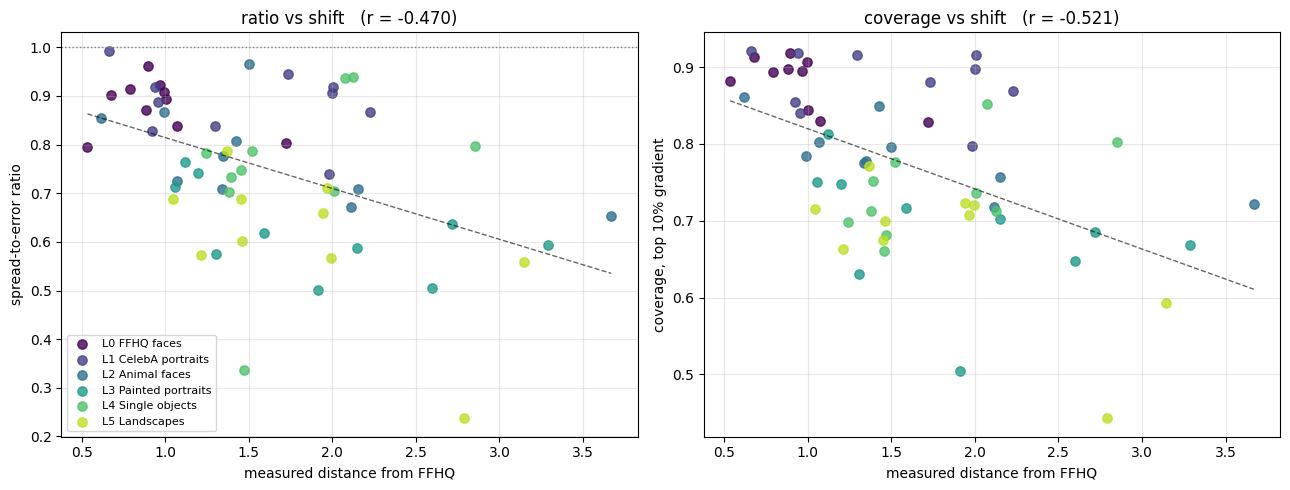

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
colors = plt.cm.viridis(np.linspace(0, 0.9, 6))

for lvl in range(6):
    ax[0].scatter(D[lvl], R[lvl][:,2], color=colors[lvl],
                  label=f'L{lvl} {NAMES[lvl]}', s=45, alpha=0.8)
    ax[1].scatter(D[lvl], COV[lvl]['top'], color=colors[lvl], s=45, alpha=0.8)

for a, y, lab in [(ax[0], ratio_all, 'spread-to-error ratio'),
                  (ax[1], top_all, 'coverage, top 10% gradient')]:
    m, b = np.polyfit(dist_all, y, 1)
    xs = np.linspace(dist_all.min(), dist_all.max(), 50)
    a.plot(xs, m*xs + b, 'k--', lw=1, alpha=0.6)
    a.set_xlabel('measured distance from FFHQ')
    a.set_ylabel(lab)
    a.grid(alpha=0.3)

ax[0].axhline(1.0, color='grey', ls=':', lw=1)
ax[0].set_title(f'ratio vs shift   (r = {np.corrcoef(dist_all, ratio_all)[0,1]:+.3f})')
ax[1].set_title(f'coverage vs shift   (r = {np.corrcoef(dist_all, top_all)[0,1]:+.3f})')
ax[0].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.savefig('/kaggle/working/phaseA_curve.png', dpi=150)
plt.show()

In [8]:
import json
out = {
  'lambda': float(lam),
  'levels': {
    str(l): {
      'name': NAMES[l],
      'ratio_mean': float(R[l][:,2].mean()),
      'ratio_sd': float(R[l][:,2].std()),
      'spread': float(R[l][:,0].mean()),
      'error': float(R[l][:,1].mean()),
      'cov_pooled': float(COV[l]['all'].mean()),
      'cov_top10': float(COV[l]['top'].mean()),
      'cov_bottom10': float(COV[l]['bottom'].mean()),
      'cov_random10': float(COV[l]['random'].mean()),
      'distance': float(D[l].mean()),
      'distance_sd': float(D[l].std()),
    } for l in range(6)
  },
  'correlations': {
    'ratio': float(np.corrcoef(dist_all, ratio_all)[0,1]),
    'cov_top10': float(np.corrcoef(dist_all, top_all)[0,1]),
    'cov_pooled': float(np.corrcoef(dist_all, pool_all)[0,1]),
  }
}
with open('/kaggle/working/phaseA_results.json','w') as f:
    json.dump(out, f, indent=2)
print(json.dumps(out['correlations'], indent=2))
print('saved')

{
  "ratio": -0.46953692914558903,
  "cov_top10": -0.5211275958607222,
  "cov_pooled": -0.42745516337146355
}
saved
